# Бинарная классификация табличных данных - прогнозирование сердечных заболеваний


Пример:

In [3]:
x=6+7
print (x)

13


In [5]:
q=2-2+8
print (f"2-2+8={q}")

2-2+8=8


In [3]:
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt


In [2]:
keras.utils.set_random_seed(42)

In [4]:
df = pd.read_csv("heart.csv")

In [5]:
df.shape

(303, 14)

In [6]:
df.head(3)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,fixed,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,normal,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,reversible,0


In [7]:
df.target.value_counts(normalize=True, dropna=False)

target
0    0.726073
1    0.273927
Name: proportion, dtype: float64

In [8]:
categorical_variables = ['sex', 'cp', 'fbs', 'restecg','exang', 'ca', 'thal']
numerics = ['age', 'trestbps','chol', 'thalach', 'oldpeak', 'slope']

In [9]:

df1 = pd.get_dummies(df, columns = categorical_variables, dtype=int)

In [10]:
df1.head(3)

,age,trestbps,chol,thalach,oldpeak,slope,target,sex_0,sex_1,cp_0,...,exang_1,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_fixed,thal_normal,thal_reversible
0,63,145,233,150,2.3,3,0,0,1,0,...,0,1,0,0,0,0,0,1,0,0
1,67,160,286,108,1.5,2,1,0,1,0,...,1,0,0,0,1,0,0,0,1,0
2,67,120,229,129,2.6,2,0,0,1,0,...,1,0,0,1,0,0,0,0,0,1


In [11]:
test_df = df1.sample(frac=0.2, random_state=42)
train_df = df1.drop(test_df.index)
train_df.shape

(242, 30)

In [12]:
test_df.shape

(61, 30)

In [13]:
means = train_df[numerics].mean()
sd = train_df[numerics].std()

In [14]:
means

age          54.268595
trestbps    131.995868
chol        246.512397
thalach     149.805785
oldpeak       1.032645
slope         1.590909
dtype: float64

In [15]:
train_df[numerics]= (train_df[numerics] - means)/sd
test_df[numerics]= (test_df[numerics] - means)/sd

In [17]:
train_df.head()

,age,trestbps,chol,thalach,oldpeak,slope,target,sex_0,sex_1,cp_0,...,exang_1,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_fixed,thal_normal,thal_reversible
0,0.963746,0.721939,-0.278690,0.008396,1.083461,2.226814,0,0,1,0,...,0,1,0,0,0,0,0,1,0,0
1,1.405254,1.554681,0.814423,-1.807247,0.399542,0.646494,1,0,1,0,...,1,0,0,0,1,0,0,0,1,0
2,1.405254,-0.665964,-0.361189,-0.899426,1.339930,0.646494,0,0,1,0,...,1,0,0,1,0,0,0,0,0,1
3,-1.906055,-0.110803,0.071931,1.607891,2.109339,2.226814,0,0,1,0,...,0,1,0,0,0,0,0,0,1,0
4,-1.464547,-0.110803,-0.876809,0.959447,0.314052,-0.933825,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0


In [18]:
train = train_df.to_numpy()
test = test_df.to_numpy()

In [19]:
train_X = np.delete(train, 6, axis=1)
test_X = np.delete(test, 6, axis=1)

In [20]:
train_X.shape, test_X.shape

((242, 29), (61, 29))

In [ ]:
train_y = train[:, 6]
test_y = test[:, 6]
train_y.shape, test_y.shape


In [22]:
num_columns = train_X.shape[1]
input = keras.Input(shape=(num_columns,))
h = keras.layers.Dense(16, activation="relu", name="Hidden")(input)
output = keras.layers.Dense(1, activation="sigmoid", name="Output")(h)
model = keras.Model(input, output)
model.summary()

E0000 00:00:1793014605.019747   42893 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden (Dense)                  │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
(29 + 1)* 16 + (16 + 1) * 1

497

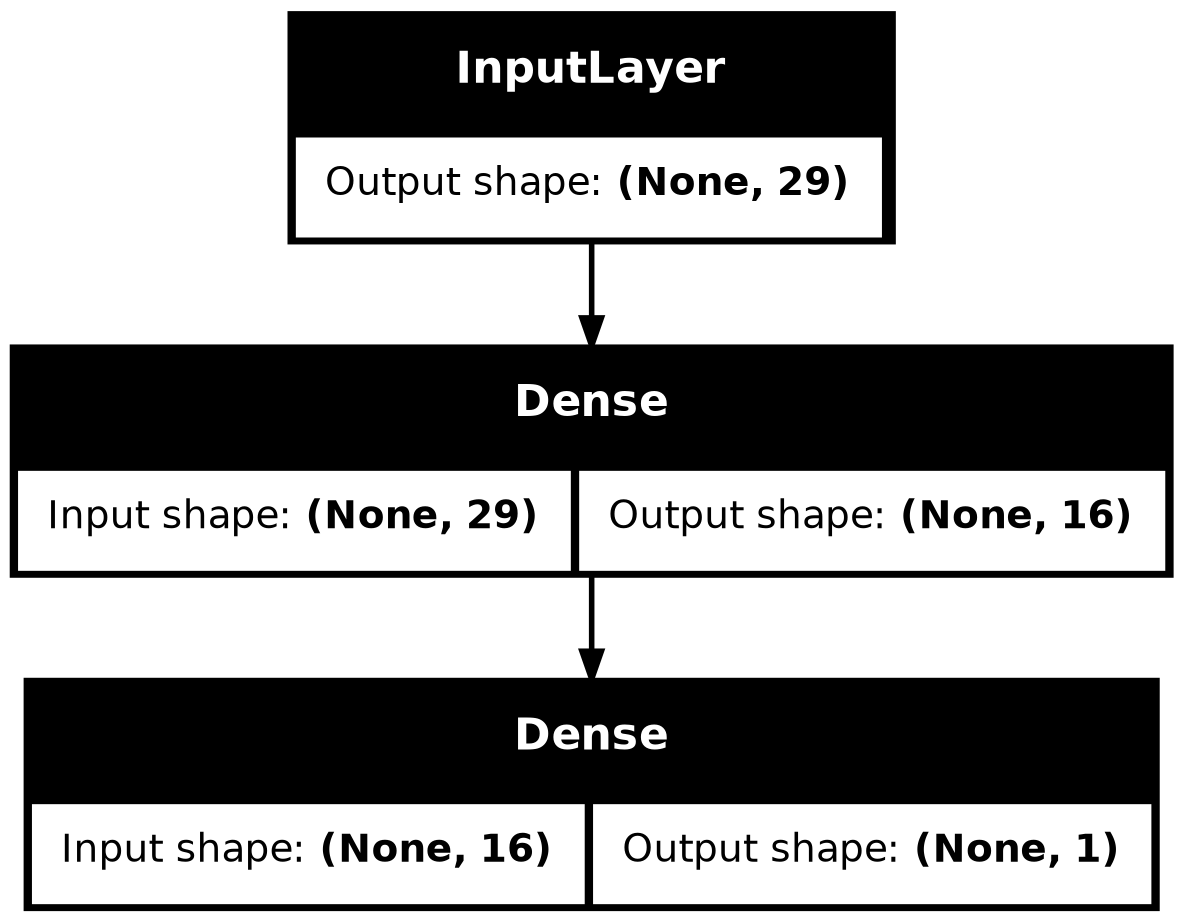

In [24]:
keras.utils.plot_model(model, show_shapes=True)

In [25]:
model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])
history = model.fit(train_X,              
                    train_y,              
                    epochs=300,           
                    batch_size=32,        
                    verbose=1,            
                    validation_split=0.2)

Epoch 1/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.4093 - loss: 0.7911 - val_accuracy: 0.4898 - val_loss: 0.7203
Epoch 2/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5233 - loss: 0.7211 - val_accuracy: 0.6122 - val_loss: 0.6773
Epoch 3/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6373 - loss: 0.6638 - val_accuracy: 0.6327 - val_loss: 0.6410
Epoch 4/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6736 - loss: 0.6151 - val_accuracy: 0.6735 - val_loss: 0.6112
Epoch 5/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7306 - loss: 0.5744 - val_accuracy: 0.7143 - val_loss: 0.5866
Epoch 6/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7720 - loss: 0.5405 - val_accuracy: 0.7551 - val_loss: 0.5662
Epoch 7/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7876 - loss: 0.5121 - val_accuracy: 0.7347 - val_loss: 0.5493
Epoch 8/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7927 - loss: 0.4880 - val_accuracy: 0.7347 - val_loss: 0.535

In [26]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

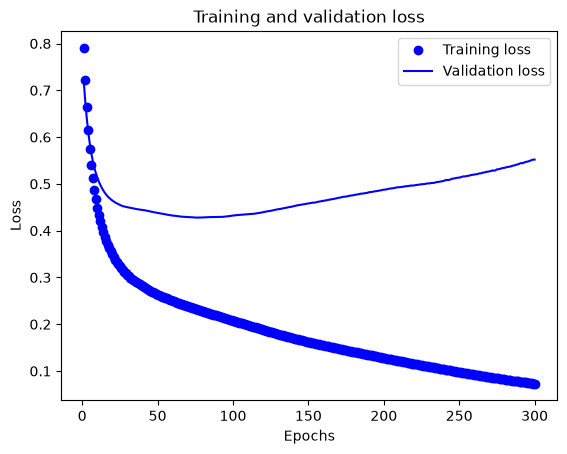

In [27]:
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

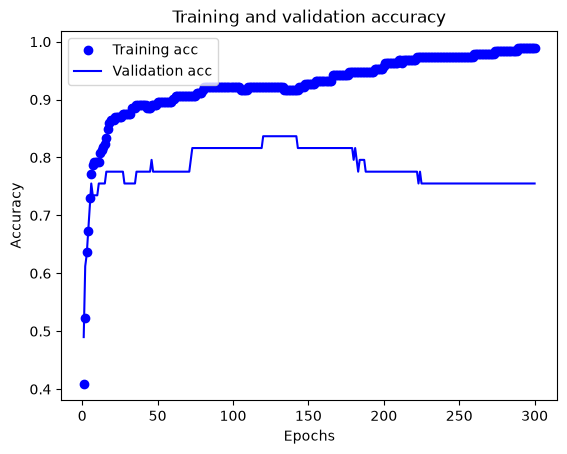

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8197 - loss: 0.5507


[0.5507304668426514, 0.8196721076965332]

In [28]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
model.evaluate(test_X, test_y)